# LSTM Experiment
- **Group Name**: MVPs
- **Course:** Advanced Deep Learning - AIGC-5500-0NA
- **Professor**: Hossein Pourmodheji
- **Owner:** Daniel Alejandro Castillo Martin
---


Starter notebook: shared data loading and batch verification are provided; model implementation, training, and results remain to be completed. No results are fabricated.

Reuse the prepared Enron partitions and training vocabulary. Select configurations on validation data and reserve test evaluation for frozen final models.


## 1. Initial Configuration


### 1.1. Imports, Paths, and Device


In [36]:
# Import required libraries
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn

# Locate the repository from either its root or the notebooks folder
current_dir = Path.cwd().resolve()
PROJECT_ROOT = current_dir if (current_dir / 'src').is_dir() else current_dir.parent
if not (PROJECT_ROOT / 'src').is_dir():
    raise FileNotFoundError('Place this notebook in the repository notebooks folder.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import shared project modules
from src.config import BATCH_SIZE, TRAINING_SEEDS
from src.data import load_prepared_data
from src.reproducibility import set_seed
from src.text import EncodedTextDataset, make_data_loader
from src.lstm_model import LSTMClassifier
from src.evaluation import classification_metrics, evaluate_model
from src.training import fit_model
from src.config import (TUNING_SEED, WEIGHT_DECAY, MAX_GRAD_NORM, SELECTION_METRIC)
from src.config import EPOCHS, LEARNING_RATES
from src.benchmark import benchmark_inference

# Use CUDA when it is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Print the runtime and selected device
print('Python:', sys.version.split()[0])
print('Interpreter:', sys.executable)
print('PyTorch:', torch.__version__)
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

Python: 3.12.10
Interpreter: c:\Users\dancm\OneDrive\Documentos\humber-aigc-postgraduate\aigc-5500-advanced-deep-learning\midterm-project\AIGC5500-Midterm-Project\.venv\Scripts\python.exe
PyTorch: 2.9.1+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


### 1.2. Experiment Configuration


In [13]:
# Name this experiment and its owner
MODEL_NAME = 'lstm'
OWNER = 'Daniel Alejandro Castillo Martin'

# Reset randomness before the first run
set_seed(TRAINING_SEEDS[0])

# Point to the shared prepared data and this model's output folders
PREPARED_DATA_DIR = PROJECT_ROOT / 'data' / 'processed' / 'enron'
RESULTS_DIR = PROJECT_ROOT / 'results' / 'enron' / MODEL_NAME
CHECKPOINT_DIR = PROJECT_ROOT / 'checkpoints' / 'enron' / MODEL_NAME

# Show the shared training seeds and batch size
print('Training seeds:', TRAINING_SEEDS)
print('Batch size:', BATCH_SIZE)

Training seeds: (42, 123, 2026)
Batch size: 64


## 2. Load Shared Prepared Data


Run `01_data_preparation.ipynb` once before this notebook. The saved preprocessing metadata controls sequence length; this notebook does not refit the vocabulary.


In [14]:
# Load the saved splits, vocabulary, and metadata
prepared = load_prepared_data(PREPARED_DATA_DIR)

# Keep the cleaned partitions
splits = prepared['splits']

# Keep the training vocabulary
vocabulary = prepared['vocabulary']

# Keep the preprocessing configuration
metadata = prepared['metadata']

# Use the saved sequence length instead of choosing a new one
MAX_LENGTH = metadata['max_length']

# Confirm the vocabulary size and reserved token IDs
assert len(vocabulary) == metadata['vocabulary_size']
assert vocabulary['<pad>'] == 0 and vocabulary['<unk>'] == 1
# Confirm each split still has the saved number of rows
for name, expected_size in metadata['split_sizes'].items():
    assert len(splits[name]) == expected_size

# Show the loaded split sizes
pd.DataFrame([{'split': name, 'rows': len(part)} for name, part in splits.items()])

,split,rows
0,train,22524
1,validation,5632
2,test,1981


In [15]:
# Print dataset information
print('Vocabulary size:', len(vocabulary))
print('Maximum length:', MAX_LENGTH)
print('Dataset:', metadata['dataset_id'])
print('Dataset revision:', metadata['dataset_revision'])

Vocabulary size: 10000
Maximum length: 256
Dataset: SetFit/enron_spam
Dataset revision: main


### 2.1. Encode Development Partitions


Only training and validation are encoded. Recreate the training loader for each seed; keep validation order fixed.


In [16]:
# Encode train and validation only
encoded_datasets = {
    name: EncodedTextDataset(
        texts = splits[name]['text'],
        labels = splits[name]['label'],
        vocabulary = vocabulary,
        max_length = MAX_LENGTH) for name in ('train', 'validation')
    }

# Keep validation order fixed
validation_loader = make_data_loader(encoded_datasets['validation'], batch_size = BATCH_SIZE, shuffle = False, seed = TRAINING_SEEDS[0])

# Inspect one validation batch
example_batch = next(iter(validation_loader))
for name, tensor in example_batch.items():
    print(name, tuple(tensor.shape))

# Recreate the training loader inside every seeded run, before training.
# Do not encode or evaluate the test partition during development.

tokens (64, 256)
lengths (64,)
labels (64,)


## 3. LSTM Architecture


- The classifier uses learned 64-dimensional token embeddings and a single unidirectional LSTM with 128 hidden units. Packed sequences exclude padding from recurrent processing.

- The final hidden state represents each email. Dropout is applied before a linear layer produces two raw scores: non-spam and spam.

- The main model initializes the LSTM biases to zero. The proposed ablation changes only the effective forget-gate bias from zero to one.

In [17]:
# Define the model configuration
MODEL_CONFIG = {'embed_dim': 64, 'hidden_dim': 128, 'dropout': 0.1}

# Set seed for reproducibility
set_seed(TRAINING_SEEDS[0])

# Define the model
model = LSTMClassifier(vocab_size = len(vocabulary), **MODEL_CONFIG, forget_bias = 0.0).to(device)

# Calculate the number of trainable parameters
parameter_count = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

# Print the model and the number of trainable parameters
print(model)
print(f'Trainable parameters: {parameter_count:,}')

LSTMClassifier(
  (embedding): Embedding(10000, 64, padding_idx=0)
  (lstm): LSTM(64, 128, batch_first=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (classifier): Linear(in_features=128, out_features=2, bias=True)
)
Trainable parameters: 739,586


### 3.1. Verify Output Shape and Padding Handling

The untrained model is checked for finite outputs and the expected two-score output shape. Additional right padding must not change its predictions when the original sequence lengths are preserved.

In [18]:
# Evaluate the model
model.eval()

# Get the tokens and lengths from the example batch
tokens = example_batch['tokens'].to(device)
lengths = example_batch['lengths']

# Evaluate the model with inference mode
with torch.inference_mode():
    logits = model(tokens, lengths)
    
# Check the output shape and the finiteness of the logits
assert logits.shape == (len(lengths), 2)
assert torch.isfinite(logits).all().item()

# Print the output shape and the first three score pairs
print('Output shape:', logits.shape)
print('First three score pairs:')
print(logits[:3].cpu())

Output shape: torch.Size([64, 2])
First three score pairs:
tensor([[ 0.1027,  0.0393],
        [ 0.1257,  0.0387],
        [-0.0487,  0.0672]])


In [19]:
# Append ten padding positions without changing the real lengths.
extra_padding = torch.zeros((tokens.shape[0], 10), dtype = tokens.dtype, device = device)

# Concatenate the extra padding to the tokens
padded_tokens = torch.cat([tokens, extra_padding], dim = 1)

# Evaluate the model with the padded tokens
with torch.inference_mode():
    padded_logits = model(padded_tokens, lengths)

# Check if the logits are close to the original logits
torch.testing.assert_close(logits, padded_logits, rtol = 1e-4, atol = 1e-5)

# Print the result
print('Padding check passed: extra padding does not change the scores.')

Padding check passed: extra padding does not change the scores.


### 4.1. Verify Evaluation Metrics

A small example with known predictions verifies the shared metric calculation before it is used for model validation. Both macro F1 and spam F1 are reported explicitly to avoid confusing the two measures.

In [20]:
# Test the classification metrics
example_true = [0, 0, 1, 1]
example_pred = [0, 0, 0, 1]

example_metrics = classification_metrics(example_true, example_pred)

# Display the example metrics
display(pd.Series(example_metrics))

# Assert the example metrics are correct with a small tolerance for floating point imprecision
assert abs(example_metrics['accuracy'] - 0.75) < 1e-9
assert abs(example_metrics['macro_f1'] - 0.7333333333333334) < 1e-9
assert abs(example_metrics['spam_f1'] - 0.6666666666666666) < 1e-9
assert abs(example_metrics['spam_precision'] - 1.0) < 1e-9
assert abs(example_metrics['spam_recall'] - 0.5) < 1e-9

print('Metric checks passed.')

accuracy          0.750000
macro_f1          0.733333
spam_f1           0.666667
spam_precision    1.000000
spam_recall       0.500000
dtype: float64

Metric checks passed.


### 4.2. Development Training Run

A one-epoch development run checks that the LSTM, optimizer, validation procedure, and checkpoint saving work together. This is a pipeline check, not a completed tuning or final comparison experiment

In [21]:
# Test the classification metrics
example_true = [0, 0, 1, 1]
example_pred = [0, 0, 0, 1]

example_metrics = classification_metrics(
    example_true,
    example_pred,
)

# Display the example metrics
display(pd.Series(example_metrics))

# Assert the example metrics are correct with a small tolerance for floating point imprecision
assert abs(example_metrics['accuracy'] - 0.75) < 1e-9
assert abs(example_metrics['macro_f1'] - 0.7333333333333334) < 1e-9
assert abs(example_metrics['spam_f1'] - 0.6666666666666666) < 1e-9
assert abs(example_metrics['spam_precision'] - 1.0) < 1e-9
assert abs(example_metrics['spam_recall'] - 0.5) < 1e-9

print('Metric checks passed.')

accuracy          0.750000
macro_f1          0.733333
spam_f1           0.666667
spam_precision    1.000000
spam_recall       0.500000
dtype: float64

Metric checks passed.


In [ ]:
# Development run

development_run = fit_model(
    model_factory = lambda: LSTMClassifier(
        vocab_size = len(vocabulary),
        **MODEL_CONFIG,
        forget_bias = 0.0,
    ),
    train_dataset=encoded_datasets["train"],
    validation_loader = validation_loader,
    device = device,
    seed = TUNING_SEED,
    epochs = 1,
    learning_rate = 1e-3,
    weight_decay = WEIGHT_DECAY,
    max_grad_norm = MAX_GRAD_NORM,
    batch_size = BATCH_SIZE,
    checkpoint_path = CHECKPOINT_DIR / "development_seed42_epoch1.pt",
    history_path = RESULTS_DIR / "development_seed42_epoch1.csv",
    selection_metric = SELECTION_METRIC,
)

# Display the history
display(development_run["history"])
# Print the training time
print(f"Training time: {development_run['training_seconds']:.1f} seconds")

,epoch,seed,learning_rate,train_loss,val_accuracy,val_macro_f1,val_spam_f1,val_spam_precision,val_spam_recall,val_loss
0,1,42,0.001,0.313441,0.926491,0.926449,0.928225,0.875695,0.987459,0.21715


Training time: 10.3 seconds


### 4.3. Learning-Rate Selection

Two learning rates are compared using the same initialization seed, architecture, data partitions, and epoch budget.

Each candidate starts from scratch. The learning rate with the highest best-checkpoint validation macro F1 is selected. Candidate order resolves exact ties. Test data is not used.

In [ ]:
# Define the tuning directory and checkpoint directory
TUNING_DIR = RESULTS_DIR / 'tuning'
TUNING_CHECKPOINT_DIR = CHECKPOINT_DIR / 'tuning'

# Initialize the tuning rows list
tuning_rows = []

   # Loop through the learning rates
for learning_rate in LEARNING_RATES:
    # Define the run name
    run_name = f'lr{learning_rate:g}_seed{TUNING_SEED}'

    # Print the learning rate
    print(f'\nLearning rate: {learning_rate:g}')

    # Fit the model
    run = fit_model(
        model_factory = lambda: LSTMClassifier(
            vocab_size = len(vocabulary),
            **MODEL_CONFIG,
            forget_bias = 0.0,
        ),
        train_dataset = encoded_datasets['train'],
        validation_loader = validation_loader,
        device = device,
        seed = TUNING_SEED,
        epochs = EPOCHS,
        learning_rate = learning_rate,
        weight_decay = WEIGHT_DECAY,
        max_grad_norm = MAX_GRAD_NORM,
        batch_size = BATCH_SIZE,
        checkpoint_path = TUNING_CHECKPOINT_DIR / f'{run_name}.pt',
        history_path = TUNING_DIR / f'{run_name}_history.csv',
        selection_metric = SELECTION_METRIC,
    )

    # Append the run to the tuning rows list
    tuning_rows.append({
        'learning_rate': learning_rate,
        'seed': TUNING_SEED,
        'epochs_budget': EPOCHS,
        'best_epoch': run['best_epoch'],
        'training_seconds': run['training_seconds'],
        'checkpoint_path': (
            TUNING_CHECKPOINT_DIR / f'{run_name}.pt'
        ).relative_to(PROJECT_ROOT).as_posix(),
        'history_path': (
            TUNING_DIR / f'{run_name}_history.csv'
        ).relative_to(PROJECT_ROOT).as_posix(),
        **{
            f'val_{name}': value
            for name, value in run['best_validation_metrics'].items()
        },
    })

    # Save completed candidates as we go.
    pd.DataFrame(tuning_rows).to_csv(TUNING_DIR / 'tuning_results.csv', index = False)

    # Delete the run
    del run

# Display the tuning results
tuning_results = pd.DataFrame(tuning_rows)
tuning_results


Learning rate: 0.001
Epoch 01/5 | train loss 0.3134 | val loss 0.2171 | val macro_f1 0.9264
Epoch 02/5 | train loss 0.1364 | val loss 0.1377 | val macro_f1 0.9584
Epoch 03/5 | train loss 0.0891 | val loss 0.0870 | val macro_f1 0.9769
Epoch 04/5 | train loss 0.0660 | val loss 0.0822 | val macro_f1 0.9779
Epoch 05/5 | train loss 0.0529 | val loss 0.0846 | val macro_f1 0.9792

Learning rate: 0.0003
Epoch 01/5 | train loss 0.4311 | val loss 0.2680 | val macro_f1 0.9071
Epoch 02/5 | train loss 0.1953 | val loss 0.1809 | val macro_f1 0.9441
Epoch 03/5 | train loss 0.1314 | val loss 0.1301 | val macro_f1 0.9598
Epoch 04/5 | train loss 0.1060 | val loss 0.1766 | val macro_f1 0.9580
Epoch 05/5 | train loss 0.0945 | val loss 0.0884 | val macro_f1 0.9744


,learning_rate,seed,epochs_budget,best_epoch,training_seconds,checkpoint_path,history_path,val_accuracy,val_macro_f1,val_spam_f1,val_spam_precision,val_spam_recall,val_loss
0,0.0010,42,5,5,84.616579,checkpoints/enron/lstm/tuning/lr0.001_seed42.pt,results/enron/lstm/tuning/lr0.001_seed42_histo...,0.979226,0.979194,0.978385,0.980015,0.976761,0.084577
1,0.0003,42,5,5,47.406066,checkpoints/enron/lstm/tuning/lr0.0003_seed42.pt,results/enron/lstm/tuning/lr0.0003_seed42_hist...,0.974432,0.974391,0.973373,0.975899,0.970859,0.088405


In [29]:
# Define the selection column
selection_column = f'val_{SELECTION_METRIC}'

# idxmax selects the first candidate if scores are exactly tied.
best_index = tuning_results[selection_column].idxmax()
selected_candidate = tuning_results.loc[best_index]

# Define the selected learning rate
SELECTED_LR = float(selected_candidate['learning_rate'])

# Print the selected learning rate, best epoch, and validation metric
print(f'Selected learning rate: {SELECTED_LR:g}')
print(f'Best epoch: {int(selected_candidate['best_epoch'])}')
print(f'Validation {SELECTION_METRIC}: 'f'{selected_candidate[selection_column]:.4f}')

Selected learning rate: 0.001
Best epoch: 5
Validation macro_f1: 0.9792


## 5. Main Model and Ablation Across Three Seeds

The learning rate selected using validation macro F1 is held fixed. The main model's completed tuning run is reused for seed 42.

The ablation changes only the effective forget-gate bias from zero to one. Both variants use identical architecture, data, and training settings. Test data remains unused.

In [ ]:
# Reload the saved tuning table; no tuning is repeated.
tuning_results = pd.read_csv(TUNING_DIR / 'tuning_results.csv')

# Define the selected candidate
selected_candidate = tuning_results.loc[tuning_results[f'val_{SELECTION_METRIC}'].idxmax()]

# Define the selected learning rate
SELECTED_LR = float(selected_candidate['learning_rate'])

# Assert that the selected candidate's epochs budget is equal to the epochs budget
assert int(selected_candidate['epochs_budget']) == EPOCHS

# Initialize the validation rows list
validation_rows = []
experiment_histories = {}

# Loop through the variants and forget biases
for variant, forget_bias in (('LSTM', 0.0), ('LSTM forget bias +1', 1.0),):
    for seed in TRAINING_SEEDS:

        # If the forget bias is 0.0 and the seed is the tuning seed, reuse the completed main-model tuning run
        if forget_bias == 0.0 and seed == TUNING_SEED:
            checkpoint_path = (PROJECT_ROOT / selected_candidate['checkpoint_path'])
            history_path = (PROJECT_ROOT / selected_candidate['history_path'])

        # Otherwise, create a new run name
        else:
            run_name = (f'e{EPOCHS}_{SELECTION_METRIC}'f'_lr{SELECTED_LR:g}_seed{seed}_fb{forget_bias:g}')

            checkpoint_path = CHECKPOINT_DIR / f'{run_name}.pt'
            history_path = RESULTS_DIR / f'{run_name}_history.csv'

            # New experiments use the same configuration as tuning.
            if not checkpoint_path.exists() and not history_path.exists():
                print(f'\n{variant} | seed {seed}')

                completed_run = fit_model(
                    model_factory=lambda: LSTMClassifier(
                        vocab_size=len(vocabulary),
                        **MODEL_CONFIG,
                        forget_bias = forget_bias,
                    ),
                    train_dataset = encoded_datasets['train'],
                    validation_loader = validation_loader,
                    device = device,
                    seed = seed,
                    epochs = EPOCHS,
                    learning_rate = SELECTED_LR,
                    weight_decay = WEIGHT_DECAY,
                    max_grad_norm = MAX_GRAD_NORM,
                    batch_size = BATCH_SIZE,
                    checkpoint_path = checkpoint_path,
                    history_path = history_path,
                    selection_metric = SELECTION_METRIC
                )

                del completed_run

        # If the checkpoint path or history path does not exist, raise an error
        if not checkpoint_path.exists() or not history_path.exists():
            raise RuntimeError('Incomplete run outputs. Inspect before continuing: '
                f'{checkpoint_path}'
            )

        # Load the checkpoint and history
        checkpoint = torch.load(checkpoint_path, map_location = 'cpu', weights_only = True)
        
        # Load the history
        history = pd.read_csv(history_path)
        
        # Define the expected settings
        expected_settings = {
            'seed': seed,
            'epochs_budget': EPOCHS,
            'learning_rate': SELECTED_LR,
            'selection_metric': SELECTION_METRIC,
            'batch_size': BATCH_SIZE,
            'weight_decay': WEIGHT_DECAY,
            'max_grad_norm': MAX_GRAD_NORM,
        }

        # If the checkpoint does not match the expected settings, raise an error
        if any(checkpoint.get(key) != value for key, value in expected_settings.items()):
            raise ValueError('Saved run does not match current settings.')

        # If the history is incomplete, raise an error
        if history['epoch'].tolist() != list(range(1, EPOCHS + 1)):
            raise ValueError('Saved history is incomplete.')

        # Append the history to the experiment histories dictionary
        experiment_histories[(variant, seed)] = history

        # Append the validation row to the validation rows list
        validation_rows.append({
            'variant': variant,
            'seed': seed,
            'forget_bias': forget_bias,
            'learning_rate': SELECTED_LR,
            'epochs_budget': EPOCHS,
            'selection_metric': SELECTION_METRIC,
            'best_epoch': checkpoint['epoch'],
            'checkpoint_path': checkpoint_path.relative_to(PROJECT_ROOT).as_posix(),
            'history_path': history_path.relative_to(PROJECT_ROOT).as_posix(),
            **{f'val_{key}': value for key, value in checkpoint['validation_metrics'].items()}
            })

        # Save the accumulated results after each completed run.
        pd.DataFrame(validation_rows).to_csv(RESULTS_DIR / 'validation_per_seed.csv',index = False)

validation_results = pd.DataFrame(validation_rows)
validation_results


LSTM | seed 123
Epoch 01/5 | train loss 0.3830 | val loss 0.2333 | val macro_f1 0.9151
Epoch 02/5 | train loss 0.1657 | val loss 0.1135 | val macro_f1 0.9638
Epoch 03/5 | train loss 0.0985 | val loss 0.1090 | val macro_f1 0.9669
Epoch 04/5 | train loss 0.0740 | val loss 0.1018 | val macro_f1 0.9731
Epoch 05/5 | train loss 0.0513 | val loss 0.0757 | val macro_f1 0.9815

LSTM | seed 2026
Epoch 01/5 | train loss 0.3163 | val loss 0.2741 | val macro_f1 0.9124
Epoch 02/5 | train loss 0.1388 | val loss 0.1284 | val macro_f1 0.9660
Epoch 03/5 | train loss 0.0960 | val loss 0.1034 | val macro_f1 0.9673
Epoch 04/5 | train loss 0.0688 | val loss 0.1271 | val macro_f1 0.9694
Epoch 05/5 | train loss 0.0540 | val loss 0.0776 | val macro_f1 0.9778

LSTM forget bias +1 | seed 42
Epoch 01/5 | train loss 0.2720 | val loss 0.1515 | val macro_f1 0.9505
Epoch 02/5 | train loss 0.1186 | val loss 0.1164 | val macro_f1 0.9648
Epoch 03/5 | train loss 0.0830 | val loss 0.0847 | val macro_f1 0.9737
Epoch 04/5 

,variant,seed,forget_bias,learning_rate,epochs_budget,selection_metric,best_epoch,checkpoint_path,history_path,val_accuracy,val_macro_f1,val_spam_f1,val_spam_precision,val_spam_recall,val_loss
0,LSTM,42,0.0,0.001,5,macro_f1,5,checkpoints/enron/lstm/tuning/lr0.001_seed42.pt,results/enron/lstm/tuning/lr0.001_seed42_histo...,0.979226,0.979194,0.978385,0.980015,0.976761,0.084577
1,LSTM,123,0.0,0.001,5,macro_f1,5,checkpoints/enron/lstm/e5_macro_f1_lr0.001_see...,results/enron/lstm/e5_macro_f1_lr0.001_seed123...,0.981534,0.981517,0.980952,0.974172,0.987827,0.075668
2,LSTM,2026,0.0,0.001,5,macro_f1,5,checkpoints/enron/lstm/e5_macro_f1_lr0.001_see...,results/enron/lstm/e5_macro_f1_lr0.001_seed202...,0.977805,0.977769,0.976873,0.979955,0.973810,0.077648
3,LSTM forget bias +1,42,1.0,0.001,5,macro_f1,5,checkpoints/enron/lstm/e5_macro_f1_lr0.001_see...,results/enron/lstm/e5_macro_f1_lr0.001_seed42_...,0.980291,0.980259,0.979463,0.982554,0.976392,0.065577
4,LSTM forget bias +1,123,1.0,0.001,5,macro_f1,5,checkpoints/enron/lstm/e5_macro_f1_lr0.001_see...,results/enron/lstm/e5_macro_f1_lr0.001_seed123...,0.979936,0.979914,0.979247,0.975128,0.983401,0.078075
5,LSTM forget bias +1,2026,1.0,0.001,5,macro_f1,4,checkpoints/enron/lstm/e5_macro_f1_lr0.001_see...,results/enron/lstm/e5_macro_f1_lr0.001_seed202...,0.979936,0.979908,0.979155,0.979336,0.978975,0.083560


In [31]:
# Define the validation summary
validation_summary = (validation_results.groupby("variant")[["val_accuracy", "val_macro_f1", "val_spam_f1"]].agg(["mean", "std"]))
validation_summary.to_csv(RESULTS_DIR / "validation_summary.csv")
validation_summary.round(4)

val_accuracy         val_macro_f1         val_spam_f1  \
                            mean     std         mean     std        mean   
variant                                                                     
LSTM                      0.9795  0.0019       0.9795  0.0019      0.9787   
LSTM forget bias +1       0.9801  0.0002       0.9800  0.0002      0.9793   

                             
                        std  
variant                      
LSTM                 0.0021  
LSTM forget bias +1  0.0002

In [32]:
# Define the paired results
paired_results = validation_results.pivot(index = 'seed', columns = 'variant', values = 'val_macro_f1')
# Define the ablation minus main
paired_results['ablation_minus_main'] = paired_results['LSTM forget bias +1'] - paired_results['LSTM']
# Save the paired results
paired_results.to_csv(RESULTS_DIR / 'ablation_paired_comparison.csv')
paired_results.round(4)

variant,LSTM,LSTM forget bias +1,ablation_minus_main
seed,,,
42,0.9792,0.9803,0.0011
123,0.9815,0.9799,-0.0016
2026,0.9778,0.9799,0.0021


## 6. Final Test Evaluation

The learning rate was selected using validation macro F1. Each run uses its checkpoint with the highest validation macro F1 within the fixed five-epoch budget.

The frozen checkpoints are evaluated on the held-out test partition. Results are reported separately for each seed and summarized using the mean and sample standard deviation. Test results are not used to change the model or training settings.

In [33]:
# Encode the held-out test partition using the training vocabulary.
test_dataset = EncodedTextDataset(texts = splits['test']['text'], labels = splits['test']['label'], vocabulary = vocabulary, max_length = MAX_LENGTH)

# Define the test loader using the test dataset
test_loader = make_data_loader(test_dataset, batch_size = BATCH_SIZE, shuffle = False, seed = TUNING_SEED)

# Define the test rows list
test_rows = []

for _, row in validation_results.iterrows():
    # Recreate the architecture associated with this checkpoint
    test_model = LSTMClassifier(vocab_size = len(vocabulary), **MODEL_CONFIG, forget_bias = float(row['forget_bias'])).to(device)

    checkpoint_path = PROJECT_ROOT / row['checkpoint_path']
    checkpoint = torch.load(checkpoint_path, map_location = device, weights_only = True)
    test_model.load_state_dict(checkpoint['model_state_dict'])

    # Evaluate without updating model weights.
    metrics = evaluate_model(test_model, test_loader, device)

    # Append the test row to the test rows list
    test_rows.append({
        'variant': row['variant'],
        'seed': int(row['seed']),
        'forget_bias': float(row['forget_bias']),
        'learning_rate': float(row['learning_rate']),
        'best_epoch': int(row['best_epoch']),
        'checkpoint_path': row['checkpoint_path'],
        **{f'test_{name}': value for name, value in metrics.items()},
    })

    print(f'{row['variant']} | seed {int(row['seed'])} | 'f'test macro F1: {metrics['macro_f1']:.4f}')

    del test_model, checkpoint

# Save the test results
test_results = pd.DataFrame(test_rows)
test_results.to_csv(RESULTS_DIR / 'test_per_seed.csv', index = False)
test_results

LSTM | seed 42 | test macro F1: 0.9823
LSTM | seed 123 | test macro F1: 0.9813
LSTM | seed 2026 | test macro F1: 0.9808
LSTM forget bias +1 | seed 42 | test macro F1: 0.9833
LSTM forget bias +1 | seed 123 | test macro F1: 0.9793
LSTM forget bias +1 | seed 2026 | test macro F1: 0.9783


,variant,seed,forget_bias,learning_rate,best_epoch,checkpoint_path,test_accuracy,test_macro_f1,test_spam_f1,test_spam_precision,test_spam_recall,test_loss
0,LSTM,42,0.0,0.001,5,checkpoints/enron/lstm/tuning/lr0.001_seed42.pt,0.982332,0.982332,0.982332,0.984818,0.979859,0.067984
1,LSTM,123,0.0,0.001,5,checkpoints/enron/lstm/e5_macro_f1_lr0.001_see...,0.981323,0.981321,0.981491,0.975149,0.987915,0.068894
2,LSTM,2026,0.0,0.001,5,checkpoints/enron/lstm/e5_macro_f1_lr0.001_see...,0.980818,0.980818,0.980769,0.985758,0.975831,0.079240
3,LSTM forget bias +1,42,1.0,0.001,5,checkpoints/enron/lstm/e5_macro_f1_lr0.001_see...,0.983342,0.983342,0.983375,0.983871,0.982880,0.060177
4,LSTM forget bias +1,123,1.0,0.001,5,checkpoints/enron/lstm/e5_macro_f1_lr0.001_see...,0.979303,0.979302,0.979449,0.975050,0.983887,0.082065
5,LSTM forget bias +1,2026,1.0,0.001,4,checkpoints/enron/lstm/e5_macro_f1_lr0.001_see...,0.978294,0.978294,0.978338,0.978831,0.977845,0.097454


In [34]:
# Summarize performance across the three training seeds.
test_metric_columns = ['test_accuracy', 'test_macro_f1', 'test_spam_f1', 'test_spam_precision', 'test_spam_recall']
test_summary = test_results.groupby('variant')[test_metric_columns].agg(['mean', 'std'])
test_summary.to_csv(RESULTS_DIR / 'test_summary.csv')
test_summary.round(4)

test_accuracy         test_macro_f1         test_spam_f1  \
                             mean     std          mean     std         mean   
variant                                                                        
LSTM                       0.9815  0.0008        0.9815  0.0008       0.9815   
LSTM forget bias +1        0.9803  0.0027        0.9803  0.0027       0.9804   

                            test_spam_precision         test_spam_recall  \
                        std                mean     std             mean   
variant                                                                    
LSTM                 0.0008              0.9819  0.0059           0.9812   
LSTM forget bias +1  0.0026              0.9793  0.0044           0.9815   

                             
                        std  
variant                      
LSTM                 0.0062  
LSTM forget bias +1  0.0032

## 7. Learning Curves

- Training and validation loss curves show optimization progress.
- Validation macro F1 tracks classification performance across epochs.
- Each line represents one training seed.
- The displayed histories include the complete five-epoch budget.
- Final evaluation uses the checkpoint selected by validation macro F1.

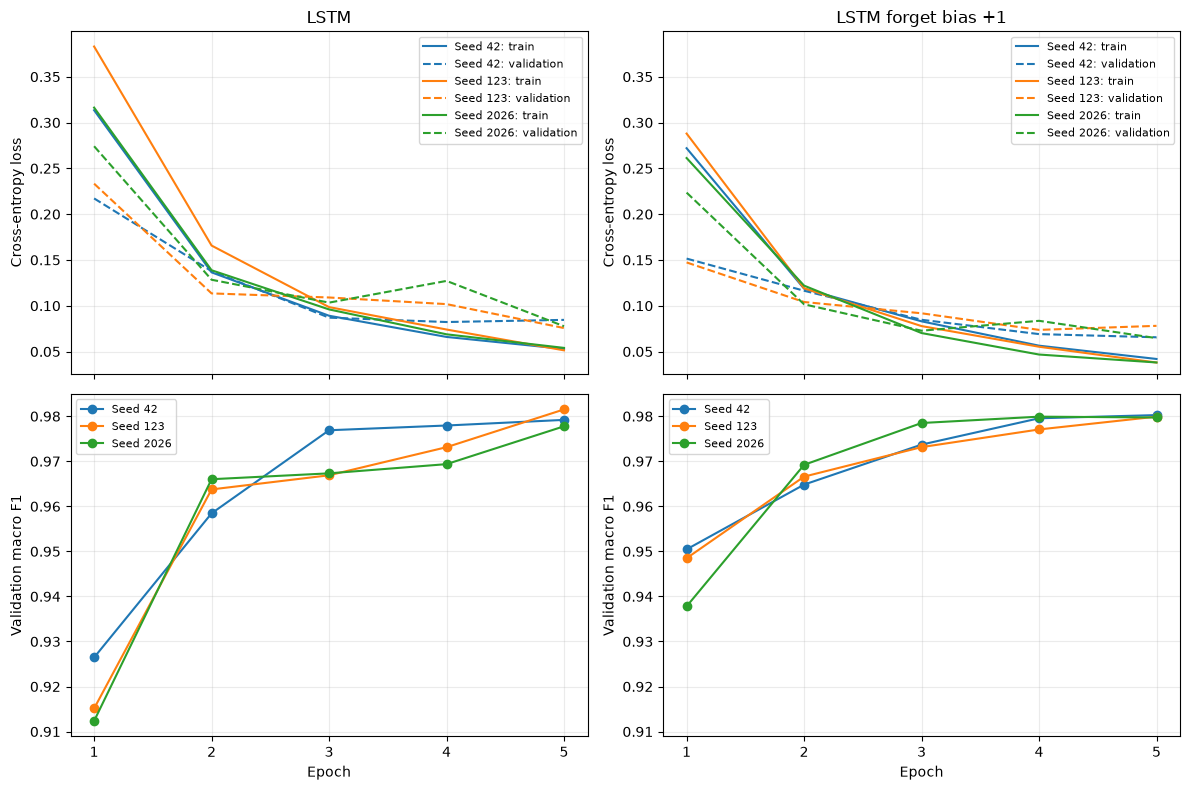

In [ ]:
# Learning curves
variants = ['LSTM', 'LSTM forget bias +1']
seed_colors = dict(zip(TRAINING_SEEDS, ['tab:blue', 'tab:orange', 'tab:green']))

fig, axes = plt.subplots(2, 2, figsize = (12, 8), sharex = True)

for column, variant in enumerate(variants):
    for seed in TRAINING_SEEDS:
        history = experiment_histories[(variant, seed)]
        color = seed_colors[seed]

        # Solid lines: training loss; dashed lines: validation loss.
        axes[0, column].plot(history['epoch'], history['train_loss'], color = color, label = f'Seed {seed}: train')
        axes[0, column].plot(history['epoch'], history['val_loss'], color = color, linestyle = '--', label = f'Seed {seed}: validation')
        axes[1, column].plot(history['epoch'], history['val_macro_f1'], color = color, marker = 'o', label = f'Seed {seed}')

    # Set the title, y-label, and x-label for the first row
    axes[0, column].set_title(variant)
    axes[0, column].set_ylabel('Cross-entropy loss')
    axes[1, column].set_ylabel('Validation macro F1')
    axes[1, column].set_xlabel('Epoch')

    # Set the x-ticks, grid, and legend for the second row
    for row in range(2):
        axes[row, column].set_xticks(range(1, EPOCHS + 1))
        axes[row, column].grid(alpha = 0.25)
        axes[row, column].legend(fontsize = 8)

# Use matching vertical scales when comparing the variants.
for row in range(2):
    lower = min(axis.get_ylim()[0] for axis in axes[row])
    upper = max(axis.get_ylim()[1] for axis in axes[row])
    for axis in axes[row]:
        axis.set_ylim(lower, upper)

fig.tight_layout()
fig.savefig(RESULTS_DIR / 'learning_curves.png', dpi = 200, bbox_inches = 'tight')
plt.show()

## 8. Inference Cost

Inference cost is measured using the seed-42 checkpoint for each variant and the same fixed validation batch. Ten warm-up passes precede fifty timed forward passes.

Timing excludes tokenization, data loading, and input transfer. Per-email time is amortized batch time, rather than single-email latency. GPU memory reports additional peak allocated memory above the model and input baseline; parameter storage is reported separately.

Comparisons across architectures require the same hardware, batch, and measurement procedure.

In [37]:
# Use identical inputs for both variants.
benchmark_batch = next(iter(validation_loader))
benchmark_rows = []

# Loop through the variants
for variant in ['LSTM', 'LSTM forget bias +1']:
    # Fix the benchmark seed independently of test performance.
    row = validation_results.loc[(validation_results['variant'] == variant) & (validation_results['seed'] == TUNING_SEED)].iloc[0]

    # Create the benchmark model
    benchmark_model = LSTMClassifier(vocab_size = len(vocabulary), **MODEL_CONFIG, forget_bias = float(row['forget_bias']))
    # Load the checkpoint
    checkpoint = torch.load(PROJECT_ROOT / row['checkpoint_path'], map_location = 'cpu', weights_only = True)
    # Load the state dictionary
    benchmark_model.load_state_dict(checkpoint['model_state_dict'])
    del checkpoint

    # Move the model to the device
    benchmark_model = benchmark_model.to(device)

    # Measure the inference cost
    measurements = benchmark_inference(benchmark_model, benchmark_batch, device)

    benchmark_rows.append({'variant': variant, 'seed': TUNING_SEED, **measurements})
    # Delete the model  
    del benchmark_model

# Create the benchmark results dataframe
benchmark_results = pd.DataFrame(benchmark_rows)
# Save the benchmark results to a CSV file
benchmark_results.to_csv(RESULTS_DIR / 'inference_cost.csv', index = False)
# Display the benchmark results
benchmark_results.T

,0,1
variant,LSTM,LSTM forget bias +1
seed,42,42
parameters,739586,739586
parameter_memory_mib,2.821297,2.821297
batch_size,64,64
padded_sequence_length,256,256
mean_real_length,176.921875,176.921875
mean_batch_ms,6.927498,7.69144
std_batch_ms,0.231279,1.330087
amortized_ms_per_email,0.108242,0.120179


## 9. Findings and Limitations

The standard LSTM achieved test macro F1 of 0.9815 ± 0.0008 across three training seeds. Initializing the forget-gate bias to +1 achieved 0.9803 ± 0.0027. Its small validation improvement did not translate into a consistent test improvement.

Both variants contain 739,586 parameters. On an NVIDIA GeForce RTX 3060 Laptop GPU, the standard LSTM averaged 6.93 ms per batch of 64 emails after warm-up. Parameter storage was 2.82 MiB, with approximately 43.15 MiB of additional peak allocated GPU memory during inference. Timing excludes preprocessing and input transfer.

The 256-token limit truncated 32.2% of training emails and removed 49.6% of training tokens. Results reflect three seeds, a five-epoch training budget, and a two-candidate learning-rate search.

Comparisons with other architectures must account for differences in training budgets, tuning procedures, and benchmark hardware.